<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/Practical_9_by_Tushar_Guleria(GF202459441).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Practical 9: KNN**

Take the iris dataset and perform KNN.

Step 1: EDA - head() , describe () , groupby()

Step 2: Feature scaling

Step 3: Training the K-NN model on the Training set

Step 4: Making the Confusion Matrix & Predicting Accuracy Score

Step 5: Making Classification Report

Step 6: Comparing Error Rate with the K Value

Step 7: Plot the error values against K values

Step 8: Finding best K Step 9: Visualize Test Result of KNN

# *Importing* *Libraries* *and* *dataset* :

This code imports the necessary data science libraries and organizes the built-in Iris dataset into a readable table with named flower species, preparing it for machine learning.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
# Load dataset
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

Step 1: EDA - head() , describe () , groupby() :

head() verifies the data loaded correctly.

describe() provides the mean, min, max, and quartiles, showing us that features have different ranges (e.g., petal length varies widely).

groupby() reveals distinct differences between species—for example, setosa has much smaller petals than virginica, indicating these features will be excellent for classification.

In [3]:
# 1. head() - View the first 5 rows
print("--- DataFrame Head ---")
print(df.head())

# 2. describe() - View statistical details
print("\n--- Statistical Summary ---")
print(df.describe())

# 3. groupby() - Compare feature averages across species
print("\n--- Groupby Species Mean ---")
print(df.groupby('species').mean())

--- DataFrame Head ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  

--- Statistical Summary ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000    

Step 2: Feature scaling:

Explanation: Distance-based algorithms like KNN are highly sensitive to the scale of the data. StandardScaler centers the data around a mean of 0 with a standard deviation of 1, preventing features with larger numerical values (like sepal length) from overpowering smaller ones (like petal width) in the distance calculation.

In [4]:
# Drop both the numeric target and the text species columns to isolate features
X = df.drop(['target', 'species'], axis=1)
y = df['target']

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Apply Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Step 3: Training the K-NN model on the Training set:

What to do: Instantiate the KNN classifier with an arbitrary initial K value (e.g., K=5) and fit it to the scaled training data.

Explanation: The model memorizes the training data. When setting n_neighbors=5, the model will classify a new data point based on the majority vote of the 5 closest training data points in the feature space.

In [5]:
# Instantiate the model with K=5
knn = KNeighborsClassifier(n_neighbors=5)

# Fit the model to the training data
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

Step 4: Making the Confusion Matrix & Predicting Accuracy Score
What to do: Use the trained model to predict the classes of the test set, then compare these predictions against the actual test labels to calculate accuracy and generate a confusion matrix.

predict() asks the model to classify the unseen test data.

accuracy_score calculates the ratio of correctly predicted instances to total instances.

The confusion_matrix creates a grid where rows represent actual classes and columns represent predicted classes. Diagonal values represent correct predictions, while off-diagonal values represent misclassifications.

In [6]:
y_pred = knn.predict(X_test_scaled)

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

print(f"\nAccuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

--- Confusion Matrix ---
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Accuracy Score: 100.00%

--- Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Step 5: Making Classification Report
What to do: Generate a comprehensive summary of the model's performance metrics for each specific class.

Explanation: The classification report breaks down the model's performance by providing precision (accuracy of positive predictions), recall (ability to find all positive instances), and the F1-score (harmonic mean of precision and recall). Adding target_names here maps the output back to our text labels, making it clear exactly which species the model struggles with or predicts perfectly.

In [7]:
print(classification_report(y_test, y_pred, target_names=['setosa', 'versicolor', 'virginica']))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Step 6: Comparing Error Rate with the K Value
What to do: Iterate through a range of K values (e.g., 1 to 40), train a new KNN model for each, record its predictions on the test set, and calculate the mean error rate.

Explanation: We cannot blindly trust that K=5 is the best choice. By testing a sequence of K values, we calculate the error rate (the proportion of incorrect predictions) for each one. Appending these rates to a list allows us to track how the model's accuracy changes as the neighborhood size grows or shrinks.

In [8]:
error_rate = []

# Loop to test K values from 1 to 40
for i in range(1, 40):
    knn_i = KNeighborsClassifier(n_neighbors=i)
    knn_i.fit(X_train_scaled, y_train)
    pred_i = knn_i.predict(X_test_scaled)
    # Average where prediction does not equal actual
    error_rate.append(np.mean(pred_i != y_test))

Step 7: Plot the error values against K values
What to do: Create a line graph displaying the K values on the X-axis and their corresponding error rates on the Y-axis.

Explanation: Visualizing the list of error rates makes it instantly obvious how K impacts performance. We look for a "sweet spot" on the graph where the error rate is at its lowest point. A K value that is too low causes overfitting, while a K value that is too high causes underfitting.

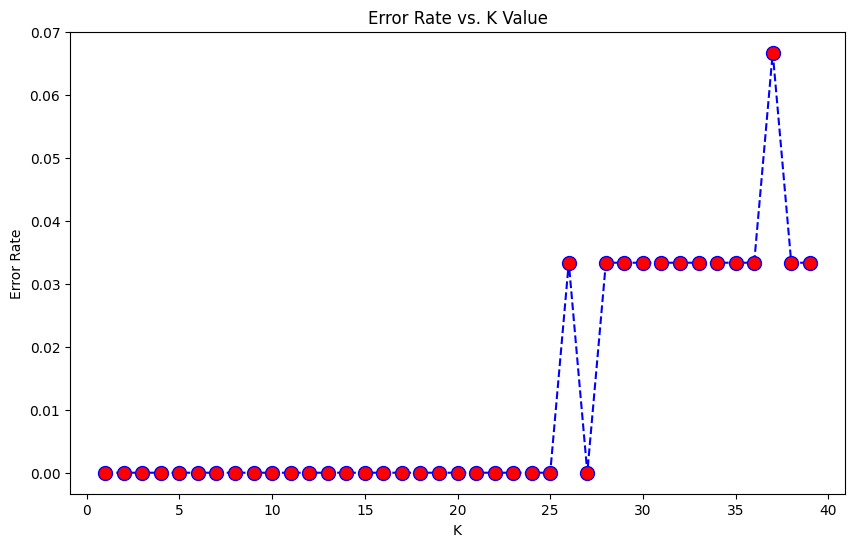

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 40), error_rate, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

In [10]:
accuracy_scores = []

for i in range(1, 40):
    knn_i = KNeighborsClassifier(n_neighbors=i)
    knn_i.fit(X_train_scaled, y_train)
    pred_i = knn_i.predict(X_test_scaled)
    # Calculate accuracy instead of error
    accuracy_scores.append(accuracy_score(y_test, pred_i))

# You would then plot accuracy_scores and look for the highest point

Step 8: Finding the Best K

What to do: Programmatically extract the K value that resulted in the lowest error rate, and retrain the final model.

Explanation: Instead of guessing, we use the minimum error from our iterative loop to select the mathematically optimal number of neighbors, ensuring the highest possible accuracy on unseen data.

In [11]:
# Find best K (adding 1 because index starts at 0 but K started at 1)
best_k = error_rate.index(min(error_rate)) + 1
print(f"The best K value is: {best_k} with an error rate of {min(error_rate):.4f}")

# Retrain with the optimal K
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
final_pred = final_knn.predict(X_test_scaled)

The best K value is: 1 with an error rate of 0.0000


Step 9: Visualize Test Result of KNN

What to do: Because the Iris dataset has 4 features (4D space), we must use Principal Component Analysis (PCA) to compress it into 2 features (2D space) to plot a decision boundary map.

Explanation: To visualize how the algorithm separates the classes, we map the 4-dimensional data onto a 2D plane. The shaded background regions represent the model's decision boundaries (where it thinks a flower is Setosa, Versicolor, or Virginica). The scattered dots are the actual test data points. If a dot's color matches the background color it sits on, the prediction was correct.

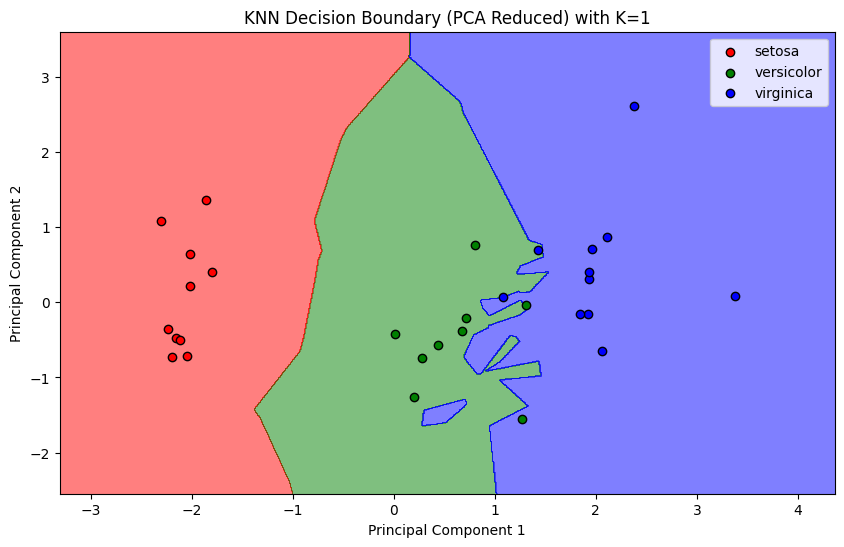

In [12]:
# Reduce data to 2 dimensions for visualization using PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Train a new KNN on the 2D data purely for visual plotting
knn_pca = KNeighborsClassifier(n_neighbors=best_k)
knn_pca.fit(X_train_pca, y_train)

# Create a meshgrid to plot decision boundaries
X_set, y_set = X_test_pca, y_test.values
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))

plt.figure(figsize=(10, 6))
plt.contourf(X1, X2, knn_pca.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.5, cmap = ListedColormap(('red', 'green', 'blue')))

# Scatter plot of the actual test data points
colors = ['red', 'green', 'blue']
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = colors[i], label = iris.target_names[j], edgecolor='black')

plt.title(f'KNN Decision Boundary (PCA Reduced) with K={best_k}')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

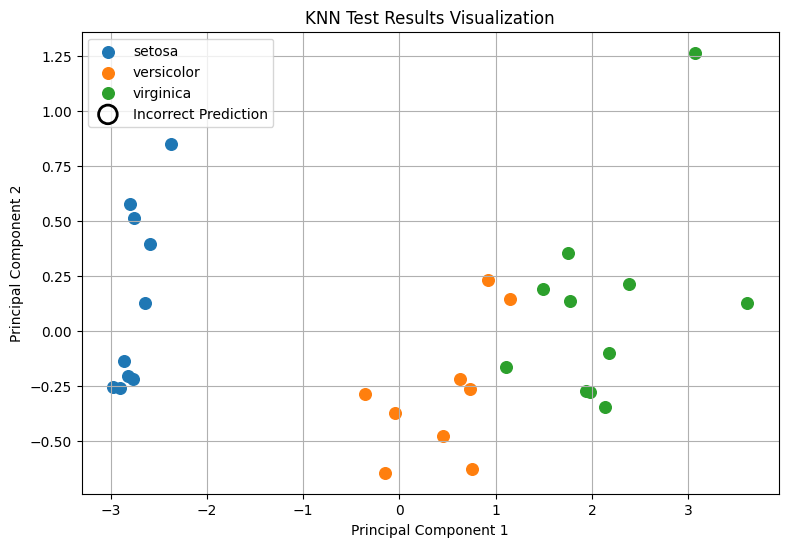

In [13]:

from sklearn.decomposition import PCA

# Reduce test data to 2 dimensions for visualization
pca = PCA(n_components=2)
X_test_2d = pca.fit_transform(X_test)

# Plot predicted classes
plt.figure(figsize=(9, 6))

for i, name in enumerate(iris.target_names):
    mask = y_pred == i

    plt.scatter(
        X_test_2d[mask, 0],
        X_test_2d[mask, 1],
        label=name,
        s=70
    )

# Highlight incorrectly classified samples
wrong = y_pred != y_test

plt.scatter(
    X_test_2d[wrong, 0],
    X_test_2d[wrong, 1],
    facecolors='none',
    edgecolors='black',
    s=180,
    linewidths=2,
    label='Incorrect Prediction'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("KNN Test Results Visualization")
plt.legend()
plt.grid(True)
plt.show()

